# 05 | PPOで路面リスク適応速度を学習（追加発展）

- 強化学習は**簡易1D走行サロゲート環境**で学習します（Genesisで直接学習するものではありません）。
- 観測：現在のリスク、直前速度、走行進捗、経過時間。行動：0〜1の目標速度比。
- 報酬：進捗、時間、過速度リスク、速度の急変に対するトレードオフ。
- Genesis実行では**安全上限速度のルール**をPPOの上位に設定し、より速く走ることを許可しません。
- 結果を「実環境での安全性証明」とは表現しないでください。

In [1]:
%pip -q install "stable-baselines3>=2.3,<3" "gymnasium>=0.29,<2" "numpy<3" "pandas>=2,<3" "matplotlib>=3.7,<4"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 5.3 MB/s eta 0:00:00


In [2]:
%%writefile road_ml.py
"""Road issue classification utilities for the PAI final project.

The Hugging Face road issues data has *issue category* labels, not defect
severity or normal-vs-abnormal labels. The curated risk score below is a
policy assumption (not learned severity, not a calibrated probability).
"""
from __future__ import annotations
import json
from pathlib import Path
import numpy as np

REPO_ID = 'Programmer-RD-AI/road-issues-detection-dataset'
RISK_BY_LABEL = {
    'Pothole Issues': 0.95,
    'Damaged Road issues': 0.75,
    'Broken Road Sign Issues': 0.70,
    'Illegal Parking Issues': 0.55,
    'Mixed Issues': 0.85,
    'Littering Garbage on Public Places Issues': 0.40,
    'Vandalism Issues': 0.35,
}


def label_risk(label: str) -> float:
    if label not in RISK_BY_LABEL:
        raise ValueError(f'Unknown dataset label: {label!r}. Revisit the risk policy mapping.')
    return float(RISK_BY_LABEL[label])


def expected_policy_risk(class_probabilities, class_names):
    """Expected *heuristic* risk: not probability of a severe physical hazard."""
    vals = np.asarray([label_risk(str(n)) for n in class_names], dtype = float)
    p = np.asarray(class_probabilities, dtype = float)
    if p.shape[-1] != len(vals):
        raise ValueError('class dimension mismatch')
    return np.sum(p*vals, axis = -1)


def select_station(current_xy, locations, scores, visited = None, policy = 'adaptive'):
    """Distance vs learned-category-dependent policy comparison.

    Note: straight-line distance is for target priority only, not obstacle-safe
    path length. The physical controller independently uses A*.
    """
    visited = set(visited or ())
    available = [s for s in locations if s not in visited]
    if not available:
        return None
    pos = np.asarray(current_xy, dtype = float)
    dd = {k:float(np.linalg.norm(pos-np.asarray(locations[k]))) for k in available}
    if policy == 'nearest':
        return min(available, key = lambda k:(dd[k], k))
    if policy != 'adaptive':
        raise ValueError('policy should be nearest or adaptive')
    return max(available, key = lambda k:(3.5*float(scores[k]) - 0.30*dd[k], -dd[k]))


def safe_speed_limit(risk, nominal_mps = 0.65):
    """Interpretable, deliberately conservative safety shield (simulation only)."""
    risk = float(np.clip(risk, 0., 1.))
    if risk >= 0.80:
        return min(nominal_mps, 0.20)
    if risk >= 0.60:
        return min(nominal_mps, 0.32)
    if risk >= 0.40:
        return min(nominal_mps, 0.48)
    return float(nominal_mps)


def save_station_manifest(items, path):
    Path(path).write_text(json.dumps(items, ensure_ascii = False, indent = 2), encoding = 'utf8')


class RoadVision:
    def __init__(self, checkpoint_path, device = 'cpu'):
        import torch
        import torchvision
        from torchvision.models import mobilenet_v3_small
        ckpt = torch.load(str(checkpoint_path), map_location = 'cpu', weights_only = True)
        self.class_names = [str(x) for x in ckpt['labels']]
        # Model weights from the training notebook; do not silently use ImageNet labels.
        self.model = mobilenet_v3_small(weights = None, num_classes = len(self.class_names))
        self.model.load_state_dict(ckpt['state_dict'])
        self.device = torch.device(device)
        self.model.to(self.device).eval()
        self.preprocess=torchvision.transforms.Compose([
            torchvision.transforms.Resize((224, 224)),
            torchvision.transforms.ToTensor(),
            torchvision.transforms.Normalize(mean = (.485, .456, .406), std = (.229, .224, .225))
        ])
        self.temperature = float(ckpt.get('temperature', 1.0))
        self.source = ckpt.get('source','unknown')

    def predict(self, img):
        import torch
        from PIL import Image
        if not isinstance(img, Image.Image):
            img = Image.open(img)
        x = self.preprocess(img.convert('RGB')).unsqueeze(0).to(self.device)
        with torch.inference_mode():
            probs = torch.softmax(self.model(x)[0]/self.temperature, dim = 0).cpu().numpy()
        predicted = int(np.argmax(probs))
        return {
            'label':self.class_names[predicted],
            'confidence':float(probs[predicted]),
            'policy_risk':float(expected_policy_risk(probs, self.class_names)),
            'category_probabilities':{n:float(p) for n, p in zip(self.class_names, probs)},
            'risk_is_heuristic':True,
        }


Writing road_ml.py


In [3]:
%%writefile speed_training.py
"""Simple risk-dependent speed *surrogate* training environment for PPO.
It is NOT Genesis physics. Policies are evaluated again in Genesis before claiming
physical-task performance.
"""
from __future__ import annotations
import numpy as np
import gymnasium as gym
from gymnasium import spaces

class SpeedEnv(gym.Env):
    metadata = {'render_modes':[]}
    def __init__(self, seed = None):
        super().__init__()
        self.observation_space = spaces.Box(0., 1., shape = (4, ), dtype = np.float32)
        self.action_space = spaces.Box(0., 1., shape = (1, ), dtype = np.float32)
        self.rng = np.random.default_rng(seed)
        self.distance = 18.
        self.dt = .4
        self.maxspeed = .65
        self.horizon = 210
        self.progress = 0.
        self.v = 0.
        self.steps = 0
        self.zones = []
    def _risk(self):
        return float(np.clip(sum(v*np.exp(-.5*((self.progress-c)/w)**2) for c, v, w in self.zones), 0, 1))
    def _obs(self):
        return np.asarray([self._risk(), self.v/self.maxspeed, min(1, self.progress/self.distance), self.steps/self.horizon], dtype = np.float32)
    def reset(self, *, seed = None, options = None):
        super().reset(seed = seed)
        self.rng = np.random.default_rng(seed) if seed is not None else self.rng
        self.progress = 0.
        self.v = 0.
        self.steps = 0
        self.zones = [(float(self.rng.uniform(3, 15)), float(self.rng.uniform(.4, .98)), float(self.rng.uniform(.6, 1.8))) for _ in range(3)]
        return self._obs(), {}
    def step(self, action):
        act = float(np.clip(np.asarray(action).reshape(-1)[0], 0, 1))
        prev = self.v
        # Acceleration-limited first-order response (surrogate dynamics)
        self.v = float(np.clip(self.v+np.clip(self.maxspeed*act-self.v, -.12, .12), 0, self.maxspeed))
        risk = self._risk()
        overspeed = max(0., self.v/self.maxspeed-(.25+.50*(1.-risk)))
        dx = self.v*self.dt
        self.progress += dx
        self.steps += 1
        completed = self.progress >= self.distance
        truncated = self.steps >= self.horizon
        reward = 4.*dx-.025 - 1.6*risk*overspeed**2-.15*abs(self.v-prev)
        if completed:
            reward += 5.
        return self._obs(), float(reward), bool(completed), bool(truncated), {'risk':risk,'mps':self.v,'dx':dx,'overspeed':overspeed}


def eval_speed_policy(policy, seeds, ppo = None):
    from road_ml import safe_speed_limit
    results = []
    for seed in seeds:
        env = SpeedEnv()
        obs, _ = env.reset(seed = int(seed))
        done = False
        traces = []
        while not done:
            risk = float(obs[0])
            if policy == 'constant':
                a = np.array([1.], dtype = np.float32)
            elif policy == 'rule':
                a = np.array([safe_speed_limit(risk, env.maxspeed)/env.maxspeed], dtype = np.float32)
            elif policy == 'ppo' and ppo is not None:
                a, _ = ppo.predict(obs, deterministic = True)
            else:
                raise ValueError(policy)
            obs, reward, terminated, truncated, info = env.step(a)
            traces.append(info)
            done = terminated or truncated
        results.append({'seed':seed,'policy':policy,'finished':env.progress>=env.distance,
                        'travel_time_s':env.steps*env.dt,'sum_risk_overspeed_sq':sum(t['risk']*t['overspeed']**2 for t in traces),
                        'mean_speed_mps':float(np.mean([t['mps'] for t in traces]))})
    return results


Writing speed_training.py


In [4]:
import numpy as np
import pandas as pd
import torch
from speed_training import SpeedEnv, eval_speed_policy
from stable_baselines3.common.env_checker import check_env
from stable_baselines3 import PPO
check_env(SpeedEnv())
print('Surrogate Gymnasium env check OK')
model=PPO('MlpPolicy',SpeedEnv(),seed=2026,verbose=1,n_steps=256,batch_size=64,
          learning_rate = 3e-4, device = 'cpu')
model.learn(total_timesteps = 15000)
model.save('ppo_speed')
print('PPO trained on abstract 1-D task, not Genesis physics')

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


Surrogate Gymnasium env check OK
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 210      |
|    ep_rew_mean     | 33.7     |
| time/              |          |
|    fps             | 994      |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 210         |
|    ep_rew_mean          | 41.8        |
| time/                   |             |
|    fps                  | 736         |
|    iterations           | 2           |
|    time_elapsed         | 0           |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008999124 |
|    clip_fraction        | 0.034       |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.42       |
|    explained_variance   | 0.0463      |
|    learning_rate        | 0.0003      |
|    loss                 | 1.88        |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0148     |
|    std                  | 0.996       |
|    value_loss           | 5.49        |
-----------------------------------------
-----------------------------------------
| rollout/                |       

          finished  travel_time_s  sum_risk_overspeed_sq  mean_speed_mps
policy                                                                  
constant       1.0          28.80                  8.748            0.63
ppo            1.0          28.80                  8.748            0.63
rule           1.0          42.62                  0.988            0.43


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


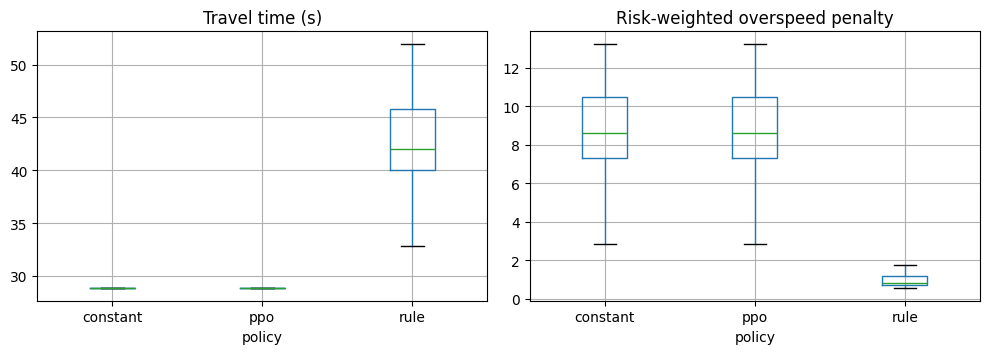

In [5]:
rows = []
for policy in ['constant','rule','ppo']:
    rows += eval_speed_policy(policy, range(1001, 1021), model if policy == 'ppo' else None)
results = pd.DataFrame(rows)
print(results.groupby('policy')[['finished','travel_time_s','sum_risk_overspeed_sq','mean_speed_mps']].mean().round(3))
results.to_csv('ppo_speed_evaluation.csv', index = False)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize = (10, 3.8))
for ax, k, title in zip(axes, ['travel_time_s','sum_risk_overspeed_sq'], ['Travel time (s)','Risk-weighted overspeed penalty']):
    results.boxplot(column = k, by = 'policy', ax = ax)
    ax.set_title(title)
plt.suptitle('')
plt.tight_layout()
plt.savefig('ppo_speed_comparison.png', dpi = 160)
plt.show()

In [6]:
from google.colab import files
files.download('ppo_speed.zip')
print('Notebook 06 can accept ppo_speed.zip optionally. Omit for rule-based speed.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Notebook 06 can accept ppo_speed.zip optionally. Omit for rule-based speed.
